# Weekly rhythm by facility
Yogyakarta · JogjaPulse · Role 4

Open this notebook in Google Colab and choose **Runtime → Run all**. The notebook includes the upstream summary tables needed for this figure. The final cell displays the result and writes a PNG to the current directory.

In [1]:
from pathlib import Path
from io import BytesIO
import base64, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display, Image

PRIMARY_PERIODS = ['2021_Dec', '2022_Jan', '2022_Feb_P1', '2022_Feb_P2']
COLORS = {
    "education_campus": "#0072B2",
    "healthcare_hospital": "#CC6677",
    "commercial_mall": "#AA4499",
    "traditional_market": "#B57700",
    "tourism_site": "#00896B",
    "transit_hub": "#674EA7",
    "baseline_candidate": "#647482",
    "mixed_use": "#503E35",
    "no_selected_facility": "#CBD2D4",
}
LABELS = {
    "education_campus": "Campuses",
    "healthcare_hospital": "Hospitals",
    "commercial_mall": "Malls",
    "traditional_market": "Markets",
    "tourism_site": "Tourism",
    "transit_hub": "Transit",
    "baseline_candidate": "Baseline candidates",
    "mixed_use": "Mixed use",
    "no_selected_facility": "No selected facility mapped",
}
MISSING = "#d9dfe2"
BREAK = pd.Timestamp("2022-01-01")

PERIOD_NAMES = {
    "2021_Dec": "December 2021",
    "2022_Jan": "January 2022",
    "2022_Feb_P1": "February 1–15",
    "2022_Feb_P2": "February 16–28",
    "2022_Mar_Apr_Exploratory": "March–April (exploratory)",
}


## Source data
Snapshot of `data/gold/category_summary.parquet`, `data/gold/mixed_use_sensitivity.parquet` generated by the merged project pipeline. Expand the folded cell to inspect the embedded data.

In [2]:
# @title Load the embedded summary tables
encoded = {'gold/category_summary': 'eNqNmM1uIzkShO/7FPMAhQaTf0neF3vY076BoJZq2kLbkiHJ05i33y9YctvG2C63q9QGJbGCwcjIoC/bh8f7w/HH5nE+H077aflv8/Nw3E+77XX+cTr/PV2evl/m67Sb7+8v0+7+6XKdzy+/bH4drneb8/Z6OC0feT0wXjdPx/385+E4728fuNxtz/N++dzpejefN7dnHebL9DDvD9vj84SHzf3pl/67O/y4+/3efLmeD7src4ypNr/m+ed++/en788s6fb+bZW701/zeftjnua/Dvv5uJv/FUO0zb/n3fR4PjxsWfru9PAwn3eH7f3mYXt/P3H/sfBg8eUKU5/sW6olxlxzDC310CtD0aolbyF7MMulMFSteU2t5VRybnz3m4VYWio9thy9e3bGgteWarTGvxyc74XpPD+ezqzpnyivp6fz4fKwuRyu8yuIzO5Jlx4zZRPGkovV0krwXlsX7NhiAlSNKfC4JIypRZaSvLSQemvCk3uItfPdnitf1hD4Ssixxuxec+plDeV5ewTh5u7p+2sesyhsy50Hl1kQQq0hBo+pZ/OouWMsqdfEQG3Z21hO5WN8qwM05ZwFq1Tz2lvxlkKKPdUBP9bGTw+he2UhK1Dn/dNO+jsizIfHp8srvB6nknS5sMbBYA88LiULnpvngRUY0QpsdcstaChDWCoRnFJASIJVq3uSGsDsfHXgNxbcAN5LREtrrN7N2/vr3U4qvztdHg/X7WuVQmjqugaz0Ra0gY0ErrG/pvkt19gzTw7Vb2BBViVVlnUTQK0x8KHkySJ7raGAmFhoywUCENnq/u8PInUU0/knlvICtLSp+Lh42pQG0Mj+t1LY7JqbZPLNrDtgLXpAHT4kEBCuZ9ScU802KKzFUUQvuZXeU4yD1sK7xjKCBGurvH7fXmaccUYBx/1hv31TWTmHN7d+mC6GSinxoFSpMUHpPRoVRImx+1kSB51RVKEhV4xhqBMniFVCbx6xiWXMWjHvhUIwxts/4MbNf+bvm//ZV0TLwmUC2iIT1iRHMarZ8Z1aOqWuorNYa85WsQRUWPRM66W7SooPg21IgdVAanUGWxaTotxz8h5zipnKs7gO9307iBWZstfjroPXYVzG1A2RQRxOJbCBrXWXTRT8J8RFx0XmWirrKT72HQodW6voNpRWF7DovnlAXSzXKcV1sO87LDuJceXl5vcwLaSZJwmvy89x0oGWp7LBGVnCWhpovZaahELFNjbdoztuBtBQQk83ITSwC1Wn5Oo62I+bVgwvF8wO0YInRu1k9biUVEjsfmQT6WPgkMVZbSUhZehFq11dC2PolBnIvPQ2lGGUbEQvIeWUe/yCZj93r24T5sPFL2Ae8zVcsfRMS6Cil85Ixag3eKRJQbHg4hLFaWqSY7rxSHGqpRW0QVWGW1/A+qg61OHqIF+S7ccuZnJYuF1ugV6mrLRI60YwKM1GMghqSPBMUsCl4qIaSrHS7bVG9DrwQTMe0OkNKCkMdwNpKTTAAOJEo17H/KmX0QaSXuLvl/TsZ3Qz6ihaKur/o0xShHlMFLXU8UWI7V1+1jq7YJKGlDooRTwFFS2GRpihSjU9kmOhH8GOX+rC9dYu+OWmDIIW4SlDVUGYPqB1WhiMx9yWtkZL7nQ9efTovNJsN7TaK7WKwKk0jeXWWYIFi0Qhz+tQP2WYQPjmvrGLKWViE0Jl320oWZUYXVEF2sQQ7toTeabQe4VF4ExLoC96pDOkPIZoO7QaFQStsn6B2w/CmNaqgtetODL6BZO5oiEyJiS0thBCkwuJXgB6HGA0FEO8ZngFxFN4QoYz4xJJRUup+RjTEJNkQ8VUY1lHuxJy7Dnk2HPICWTVqI6llJAHH9htouE2NSlfWluVpbqszYZH0G+7fJBSK+J86AO9K23w4jlgMV/g9v1mQT+q4xrJMY2JdFxwXuhSuFMaiYHdVDM1SSMOXtEhjPUh0yJfUHIDOmKhGA1ljLFMHq9VHoN6k39JBJ8ksjIRCnSV50RG9TdTg4oKraOXdsJAR5imRI6pDRloh1mGZEpkFLZGPmjWdJpQjPCbNNgRfBBv6zLpVbyfnMb85dJpDGCkgk4uxQKw/arKgTB1p4TtwmZo76k4fEtCT7Dly8QLH1GXt5V1y9gv0sV7Bfbf7fFLzvVMq7/Qii0lRdIAJxyqBLXyOHIfY4ScRXR4G1I09eYhDDy1J5RDuybKIBdbTpPE+5bEPsvuvoJ0pbLaRBnrar8ri3DDXgoXCmgDa6KDZo4F1EpdOrLiGomR7JvikLXcjuMQxkDLCmo0GgMguJmuqgTjCtaVSG5v7hHKkSfRlaAia6TY+0ItO0xuJcAQdMeagkKiUmOh8npbAm2Da+TCGU4BeWRJRU3CBwe03NIatavnnecLGQx51qZ9I61qeh9YIatLoYoKiHBgxZdoVuRCHTgHj0Qtth3o2nwbIkDNLEgBCHNZVPYZ1A/+gMAp13Q1RYKcbpvdRR0FQ9kOrRKgyNMdz8IffTn2EFHwLKKLCmaEbuoOd4XN8TeEJZqrBXBKwwkqYlnn872WpcStlKV7kGlhARpcXQdnr4vhcHgdtHEI5MBQB78j9sVFG9XiraaU0DFhzvQEiaWmYkW1GS2ra68J9ROfKi/X4lNo0xWJ1MFpRdIeD+c8K1CUEWe0gT1Dlo6+bKqoEqgclNQJN/hXtCUIDM5Nx/Sic+5boP8H3jImXg==', 'gold/mixed_use_sensitivity': 'eNq1mt1SI9kRhO/9FDyAvHH+f3zt8IWv/AYKDeodFAtiQhI7sW/vL+u0YGbdIAnbS4tlmlaruk5WVmYdjpunb4+7/df1t+mwe96uxv/Wv+3229X95jR9fT78sTq+fDlOp9X99Ph4XN0/vhxP0+Hth/X33elhfdicds/jkh9P2Pf1y347/brbT9v5guPD5jBtx3XPp4fpsJ4/azcdV0/TdrfZn2+4Wz8+f9f/HnZfH15/Nx1Ph939iXvYrdbfp+m37eaPD38/8Ujz7+envH/+fTpsvk6r6ffddtrfT38JLvj136f71bfD7mnDo98/Pz1Nh/vd5nH9tHl8XPG6G3nw4e1wq77yv8SSQ0glBddid71wKvjiY20uVed9yplTxbdaYmsp5pQa7/3Fu5BbzD20FGqvqXLO1dJiCb7xX3KV97nVYfr2fOCZ/jPK0/PLYXd8Wh93p+mHELl7jTr0MavkFWNO2Zfcsqu9tK6wQwuE6F2Prip+XdVqqzG4klMPUTG61F0onff2VHizThFfdimUkGotKfZ8KcrDZk+E64eXLz/mMSmFbbyS5TIpBFeKC0QUe/I16N4E57rzpLMRQq+Wci7jXb25GFNKCisXX0tvubboYuixWPihNL66432FB7kQ6rR9uRf+9gDz6dvL8Yd4a1jlqKMq1mAZ7I6Pi9G7mlpNFqsHCz53T/pyt1MpJlba1+yzIwzLaim1RqGBmEn5iN/zwI3Aew5g6VJWH6bN4+nhXih/eD5+2502P6KUhMauwzIb/IjWsZCE63NzXvf3qYSe+GRXyK4FSwS1hpSrcxzRclhKcFwWa/SB1dYpB5zIeEuZFACziwjY7pRWK6fDb5DKW6i5rXK1oxFqtFADCGg5twTAmoDyi/e9Eq4P1YGPaph2Aegm8JxiSd6SWHIFEz2nlnuPwZKdM7/1PIYTZP3FzH7ZHCe4cQID++1uu/mptlJyP730xe2omVg8HxQLVaZQeocRKHUogdoZRULeibequrtvY9UTEBXWWw0wRRlIaNnXnqkFz/n2H/GG9T+mL+t/+Wtwy5OLB7RGXsFG1Y+noCvUU3KPNavufEjUeInwGIvs7SKteessQ+08iiKDMkhqqaC5JWVSKa8p1h5SFGqaD5ejXSaEUAAqa22vYnk16iIyCiU3lX+IitWxtLWKKDIM5AweMG0LjZxXchsHlXbigU3BLZkvI1iQ34TtVhJviVcEu8yxntoisvHiZyf4CqY1CnhdjA4VWLR8KusLiQnR0aKNwQuzvDPMJZWrCg/+ajwWpDwDAT52CqtTc+VytO/3reDeDlJrqCWgELSUhQ5gNQWduuiVyep7N671pWXCJZmkDN6jcUVgQZ0RWc29paZz1CyMR0rhux6uwOzHBNb9qjUd/EDMdr8GMUKqdAVKejRHKoaPjTAWCfK2AuSRBwigkvIRp5BHqhOcQ9ZqbLDdaA2wH1UHPKqayFW4fZ/GvEiW3I6Xgh63BJGk0qMNcvMmDuAbCCE1Ft+z3qP6WF5iQT1AEM3gm0gzHMC/oAwarrVeijYDcUfENJgrau1DMqMTRH0Lr9/imdBoaEgGUJolAaxOQqfieAZ1smykLCrO9AIHRGMyGINUSykgzrT2QWjoGa7U7YFcye/iOFzViMvcL/hhRgZaC/2kxGWAWS3ajuAi4yG10dmsK1NckLQ1X2G2e7DaC8UKwKk0nUut8wje0cFphelyqB9mGE3402vOLqykzgBhQsFGtmBUxOH4dNSX1R0asjWfEu0hQtgKzusRaIw10BlislP0nd6DCoJeWa7I7Tt6TM+a+3hJkVi/4GZqV5QSzY6PHglBv6IJIHxrtKM9U/cgprK8tZnIQY0hunpU0VJqVfDwOsVNktelNefL0V7QOf6sc/xZ59BuwS0aWjLBZK2jO0TEeFOXsnZKIYpSq6jNG9fSb7t4EHRDdDkYPmAayQ2+1eR42ityu9wt0IzFDhOP0W4kx1D5RpuCnRRDV0/V6hKuHxgAhiSsG0qzaEHajcgDhJ2TR6XbOdoz7VAUA3hjvQoDHyiyvIKVdOSzIkNRN6/+FCRbrZeytiQQCo0SE0NPUm48UW+0QR7C+kKD0ZrHGSF2gzeTI2SwIEhzqA29Gy/H+4Efq2+H/BiBoQo6uhQGgPWLsEjC1JwioZJNZ90EqeaoNxp1oY0prih4Imx5M/KiWl/m19K62ZYrl7pUX//c7K8irnNa61taYaUoSYq9IZWWVj4HVc0nIbTc0I1QG0iEA/SrYN2hR4DjYGfqkz4y/CQCvyHvdc/S64VILxRWW0HoOtprYdmqYiGpoWKNlVi7bC7BImS9rWOSXgMRtLYYDNZiu1zkjGlZTo1G54iQwLlfUQmGC8Fe0OT+p5epcqoJc4VQETVS7IYMCo3Gi60gZcNJOskzYTFE6d3hzqAoWhyOETScxaS0JuIDj5ZavJTbi4bnfIADw2dpWjjkqm5fLVaZAtU/dY3TGrGq2SIOUcKYTosVqcW6I3a0+tYjcDl4J0xvDEVEcinUd2YIGF2vo0kSpDiyR+2g/arW3aqDhpWQVDjETH68ZR3D4mUUO34imiag7iBXkmlThCHN1QFoHgCngJXL6VzqWFLcEll6WS69G3G6qqYDsZdBOFrYHLR4Kv9mcdaYnGQJUpIEt7mmpNBRE7h6dMSoKfoxDQQoq2lfwukHPJXfjsFTQLNKEamB04kUQvOyOEHBNTlKiz0JCEnCpSlVCgrFRY2hbeCv4IcO6HKMXjY9y+feMjo67vZfH6e/ngd/d8/7xz/+1FolBaSSoXMVVEIODKeONsEugtMscaKrYDJoVvWVfRyZVfeU+lVdwXZWUchJSK1BaMJwvnUysxxzXJE0jnQWskg7qXxWugSJK1OLFi9NSSGaIQOfyigA0bRmxMfv6bJdTwImzu4RwMbqoK5g2vnqwddiuGoH3g7pLXMC2PCYcebkikVvZg5KQRlEVb9asA3qgIMvKAXYLA2kolPE/h2I6xnGNFGa2Ivu6F6p90+MlBbjph3MXvIMDQpE5go7JkYw2sfOFBEFVB+pnDImNsCZq7Cd+LjZ9xY9LEqd+tL0VOcwDrGbViwo9Hb7wGYZHdfPbqglZTuZErOenw34RCtS6fXTs5uLk7HljNe3Y25vsDDIYGWR/QRvhIJxKRn9oxmtM+x0OUpUL1DggfyYkUUMEIDXrLJbY0Qzq9EUzdc4ewnYf2a5xZDj/KVw+U8jAqwwDYQEwXxlSGwnKpHo0jKEOmhLGwQP0+P2b3e/Tt+nw93pYbO/y3fiqrvz9sN1c7DFyDB6sxqPr/AlBDRYb13yzyxalSPocACCe3gGMIKkQexywjIJ/YoahGpa3BiY8xDwGUYZFYS777eNwxbj/XkW0sdQDPdVHYzkbfY25kw5mfCNMYhjNeaL+DKkZRNPjGkoeosWo0FZEQmaQKMN+WwDCg1PSrpxKrYYNBkC/RztlSPEDGrBURLKigp9VjWaQ/hUXoOcSZo5S1/zPIAO6DNWA7dUW/CD2QIIrhLx5TUBt8+bFiMvZ3iU12kIWhzs4lboan14bIjaaRpDnUN0xdakqnjkdVtzfgyZnEY60DaWvQv1Y4qDIPHYKKcBQIufmuIshn7bQCfKdaBvnPr0UO8DE/AaNkOD9/92ouNv4wzv3o5z3GYZmtFEtLWXQgsITLlMRIXRXJXvwO01sxkm5hqCVA2wE2YwSa3+r7MsXdLP+VMjv2VKqW/HHHgEwl0bWUG2yWpKurjipCGWYFVGZBrwoIwSymI4O2wxOrRqPIneGLPKoMaTquZc1EIKnxigLXfEJnWn4zyaYkUlk2EHbWfayBkXIgWijbTwuiNHfyyaldBthu1AZXC9qlsm2vo4PRFVRbzSpeWzc4nlfpjejjlw2Bn/jgzWhD/P+Ub5KOUarhqte814Uk1ZvGOS25dIvwxeDptuaiSOSG0B+tYEkFoOt83UlkmlrlhxHQJIWRru2AbR2NSCg6WWrTMhJwC29hRcHKMqrCJOFMBo2KOxlCJGBUoOZE2Qeg+fmlsup/qGEWYPGhfC1NojskfUNAtvIEvQrDD/NzPM66XqT9seg8yLt+GP9rmG9YTBnSxX0MaxDSW1M99Zia4LnY0svPa3NKiXLshj+44nkw2DQoF3i83fOCFcFk5RQwEdb+QtDxDEuERl+y3AHP0ftW0TtP+8PCyMSQq6acNEv7IRLA/FiSaj0DHo6fbh23K/n79mdQrLwdAQmYyhBSMT5uX1jBhtcNnxUVUTBf6NjFaWA9DHqml0EwJ00uwcQqxb3wLkqYVbZ3DvuAHthXKkdA66S0h7WkhNaKnhvjGx0ksEqT8uMJh3tW+RNrQ2T96qHDypdWYg2zjHw3uzRLy39dsnXO+EffWwC9SAHOWXxfBj2JU1G9KMm9pt/7dh13Iplrfj7GFitexgGkszj035dU1BqLsgfTR2S4skIfXHNX7u7lXYstaJEuljfKNGr4Tjbopvn5h/vuu9Rtyv3su2npvGWbY/oFO0ayFeKsXFsbGxMAqtmiTxHv2RAkQ3zrEUNF1MBX3e53rDMGy51fh5uKhhkX1bHt1pCuI1/8xNMyTxIKxQtfkb8LUjz9ol19/Z6MIwHHunI6rtCGia8d0yYFyGtFvFpmP25EIBFkbQ1J/OONv71F4BLTCjksiUSaWuvCb4wiEF89DWOLTWsBCZNfKzfygaQPA2PFA6j9RvmOEtJ3n+GvHqD1U0/UDw0IVtk7zRuSveXH97lMb2Dl5FRACzwWHDd0MqkV4ZzNcEG7Napr0kOE6TNvqn/P4blJNUmg=='}
tables = {k: pd.read_csv(BytesIO(zlib.decompress(base64.b64decode(v)))) for k, v in encoded.items()}
def read(layer, name, columns):
    frame = tables[f'{layer}/{name}'].copy()
    missing = set(columns.split()) - set(frame)
    if missing:
        raise ValueError(f'{name} is missing {sorted(missing)}')
    return frame
def gold(name, columns):
    return read('gold', name, columns)
for key, frame in tables.items():
    print(key, frame.shape)
    display(frame.head(3))


gold/category_summary (28, 17)


,sampling_period,period_kind,category,subset,cells,clusters,clusters_with_ratio,cells_with_ratio,ratio_undefined,cells_shared_with_other_categories,median_ratio,ci_low,ci_high,median_restricted_share_weekday,median_restricted_share_weekend,median_period_coverage,evidence
0,2021_Dec,primary,commercial_mall,all cells,12,12,12,12,0,9,1.365225,1.216138,1.618764,0.102584,0.076836,1.0,reported
1,2021_Dec,primary,tourism_site,all cells,82,73,73,82,0,41,1.354517,1.282362,1.382522,0.049027,0.036250,1.0,reported
2,2021_Dec,primary,transit_hub,all cells,142,128,128,142,0,94,1.306602,1.225396,1.360661,0.056177,0.042687,1.0,reported


gold/mixed_use_sensitivity (56, 17)


,sampling_period,period_kind,category,subset,cells,clusters,clusters_with_ratio,cells_with_ratio,ratio_undefined,cells_shared_with_other_categories,median_ratio,ci_low,ci_high,median_restricted_share_weekday,median_restricted_share_weekend,median_period_coverage,evidence
0,2021_Dec,primary,commercial_mall,all cells,12,12,12,12,0,9,1.365225,1.216138,1.618764,0.102584,0.076836,1.0,reported
1,2021_Dec,primary,tourism_site,all cells,82,73,73,82,0,41,1.354517,1.282378,1.387873,0.049027,0.036250,1.0,reported
2,2021_Dec,primary,transit_hub,all cells,142,128,128,142,0,94,1.306602,1.224090,1.360661,0.056177,0.042687,1.0,reported


## Build the figure
Each category appears within a sampling period. A median above 1 indicates higher relative presence on ordinary weekdays. The diamond shows the single-category subset. Read cell and site-cluster counts beside each row.

In [3]:
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlecolor': '#224853'})

def heading(fig, title, description):
    fig.suptitle(
        title + "\n" + description,
        x=0.025,
        ha="left",
        fontsize=15.5,
        color="#163c45",
    )


def save(fig, path):
    fig.savefig(path, dpi=155, bbox_inches="tight", facecolor="white")
    plt.close(fig)


def rhythm(path):
    table = gold(
        "category_summary",
        "sampling_period category median_ratio ci_low ci_high cells_with_ratio clusters evidence",
    )
    sensitivity = gold(
        "mixed_use_sensitivity", "sampling_period category subset median_ratio evidence"
    )
    periods = [p for p in PRIMARY_PERIODS if p in set(table.sampling_period)] + sorted(
        set(table.sampling_period) - set(PRIMARY_PERIODS)
    )
    cats = [c for c in LABELS if c in set(table.category)]
    fig, axes = plt.subplots(
        (len(periods) + 1) // 2,
        2,
        figsize=(16, 3.8 * ((len(periods) + 1) // 2)),
        layout="constrained",
        squeeze=False,
    )
    for ax, period in zip(axes.flat, periods):
        rows = (
            table[table.sampling_period.eq(period)].set_index("category").reindex(cats)
        )
        overlay = sensitivity[
            (sensitivity.sampling_period == period)
            & (sensitivity.subset == "single-category only")
            & (sensitivity.evidence == "reported")
        ].set_index("category")
        for i, (cat, row) in enumerate(rows.iterrows()):
            if row.evidence == "reported":
                ax.barh(i, row.median_ratio - 1, left=1, color=COLORS[cat], height=0.48)
                ax.plot([row.ci_low, row.ci_high], [i, i], color="#14242b", lw=2.5)
            if cat in overlay.index:
                ax.scatter(
                    overlay.at[cat, "median_ratio"],
                    i,
                    marker="D",
                    s=28,
                    color="white",
                    edgecolor="#182933",
                    zorder=4,
                )
            counts = (
                "no eligible cells"
                if pd.isna(row.cells_with_ratio)
                else f"{int(row.cells_with_ratio):,} / {int(row.clusters):,}"
            )
            ax.text(
                1.02,
                i,
                ("withheld   " if str(row.evidence).startswith("withheld") else "")
                + counts,
                transform=ax.get_yaxis_transform(),
                va="center",
                fontsize=8,
            )
        ax.set_yticks(range(len(cats)), [LABELS[c] for c in cats])
        for tick_label, cat_key in zip(ax.get_yticklabels(), cats):
            if cat_key == "education_campus":
                tick_label.set_fontweight("bold")
                tick_label.set_color("#005689")
        ax.invert_yaxis()
        ax.axvline(1, color="#52616a", ls="--", lw=1)
        ax.set_title(
            PERIOD_NAMES.get(period, period), loc="left", fontweight="bold", pad=18
        )
        ax.text(1.02, 1.02, "Cells / clusters", transform=ax.transAxes, fontsize=8)
        ax.grid(axis="x", alpha=0.14)
        ax.set_axisbelow(True)
        ax.set_xlabel("Weekday / weekend share")
    bounds = pd.concat([table.ci_low, table.ci_high, sensitivity.median_ratio]).dropna()
    for ax in list(axes.flat)[: len(periods)]:
        ax.set_xlim(min(1, bounds.min()) - 0.05, max(1, bounds.max()) + 0.05)
    for ax in list(axes.flat)[len(periods) :]:
        ax.set_visible(False)
    legend_handles = [
        Patch(facecolor="#0072B2", label="All eligible cells (≥90% coverage)"),
        Line2D([0], [0], color="#14242b", lw=2.5, label="95% site-cluster bootstrap CI"),
        Line2D(
            [0],
            [0],
            marker="D",
            color="none",
            markerfacecolor="white",
            markeredgecolor="#182933",
            markersize=6,
            label="Single-category cells only",
        ),
        Line2D([0], [0], color="#52616a", ls="--", lw=1, label="1.0 = Equal weekday & weekend share"),
    ]
    fig.legend(
        handles=legend_handles,
        loc="outside lower center",
        frameon=True,
        facecolor="white",
        edgecolor="#d9dfe2",
        fontsize=9.5,
        ncol=4,
    )
    campus = table[
        (table.category == "education_campus") & (table.evidence == "reported")
    ]
    above = campus.median_ratio.gt(1).sum()
    result = (
        f"Campus cells leaned weekday in {above} of {len(campus)} periods with an estimate."
        if len(campus)
        else "The data did not support a campus comparison."
    )
    heading(
        fig,
        "Weekday and weekend presence by facility",
        "What we built: Bars compare weekday and weekend shares. 1.0 means equal shares.\n"
        "Lines show the range of uncertainty. Diamonds show cells with a single facility category.\n"
        f"What we found: {result}",
    )
    save(fig, path)


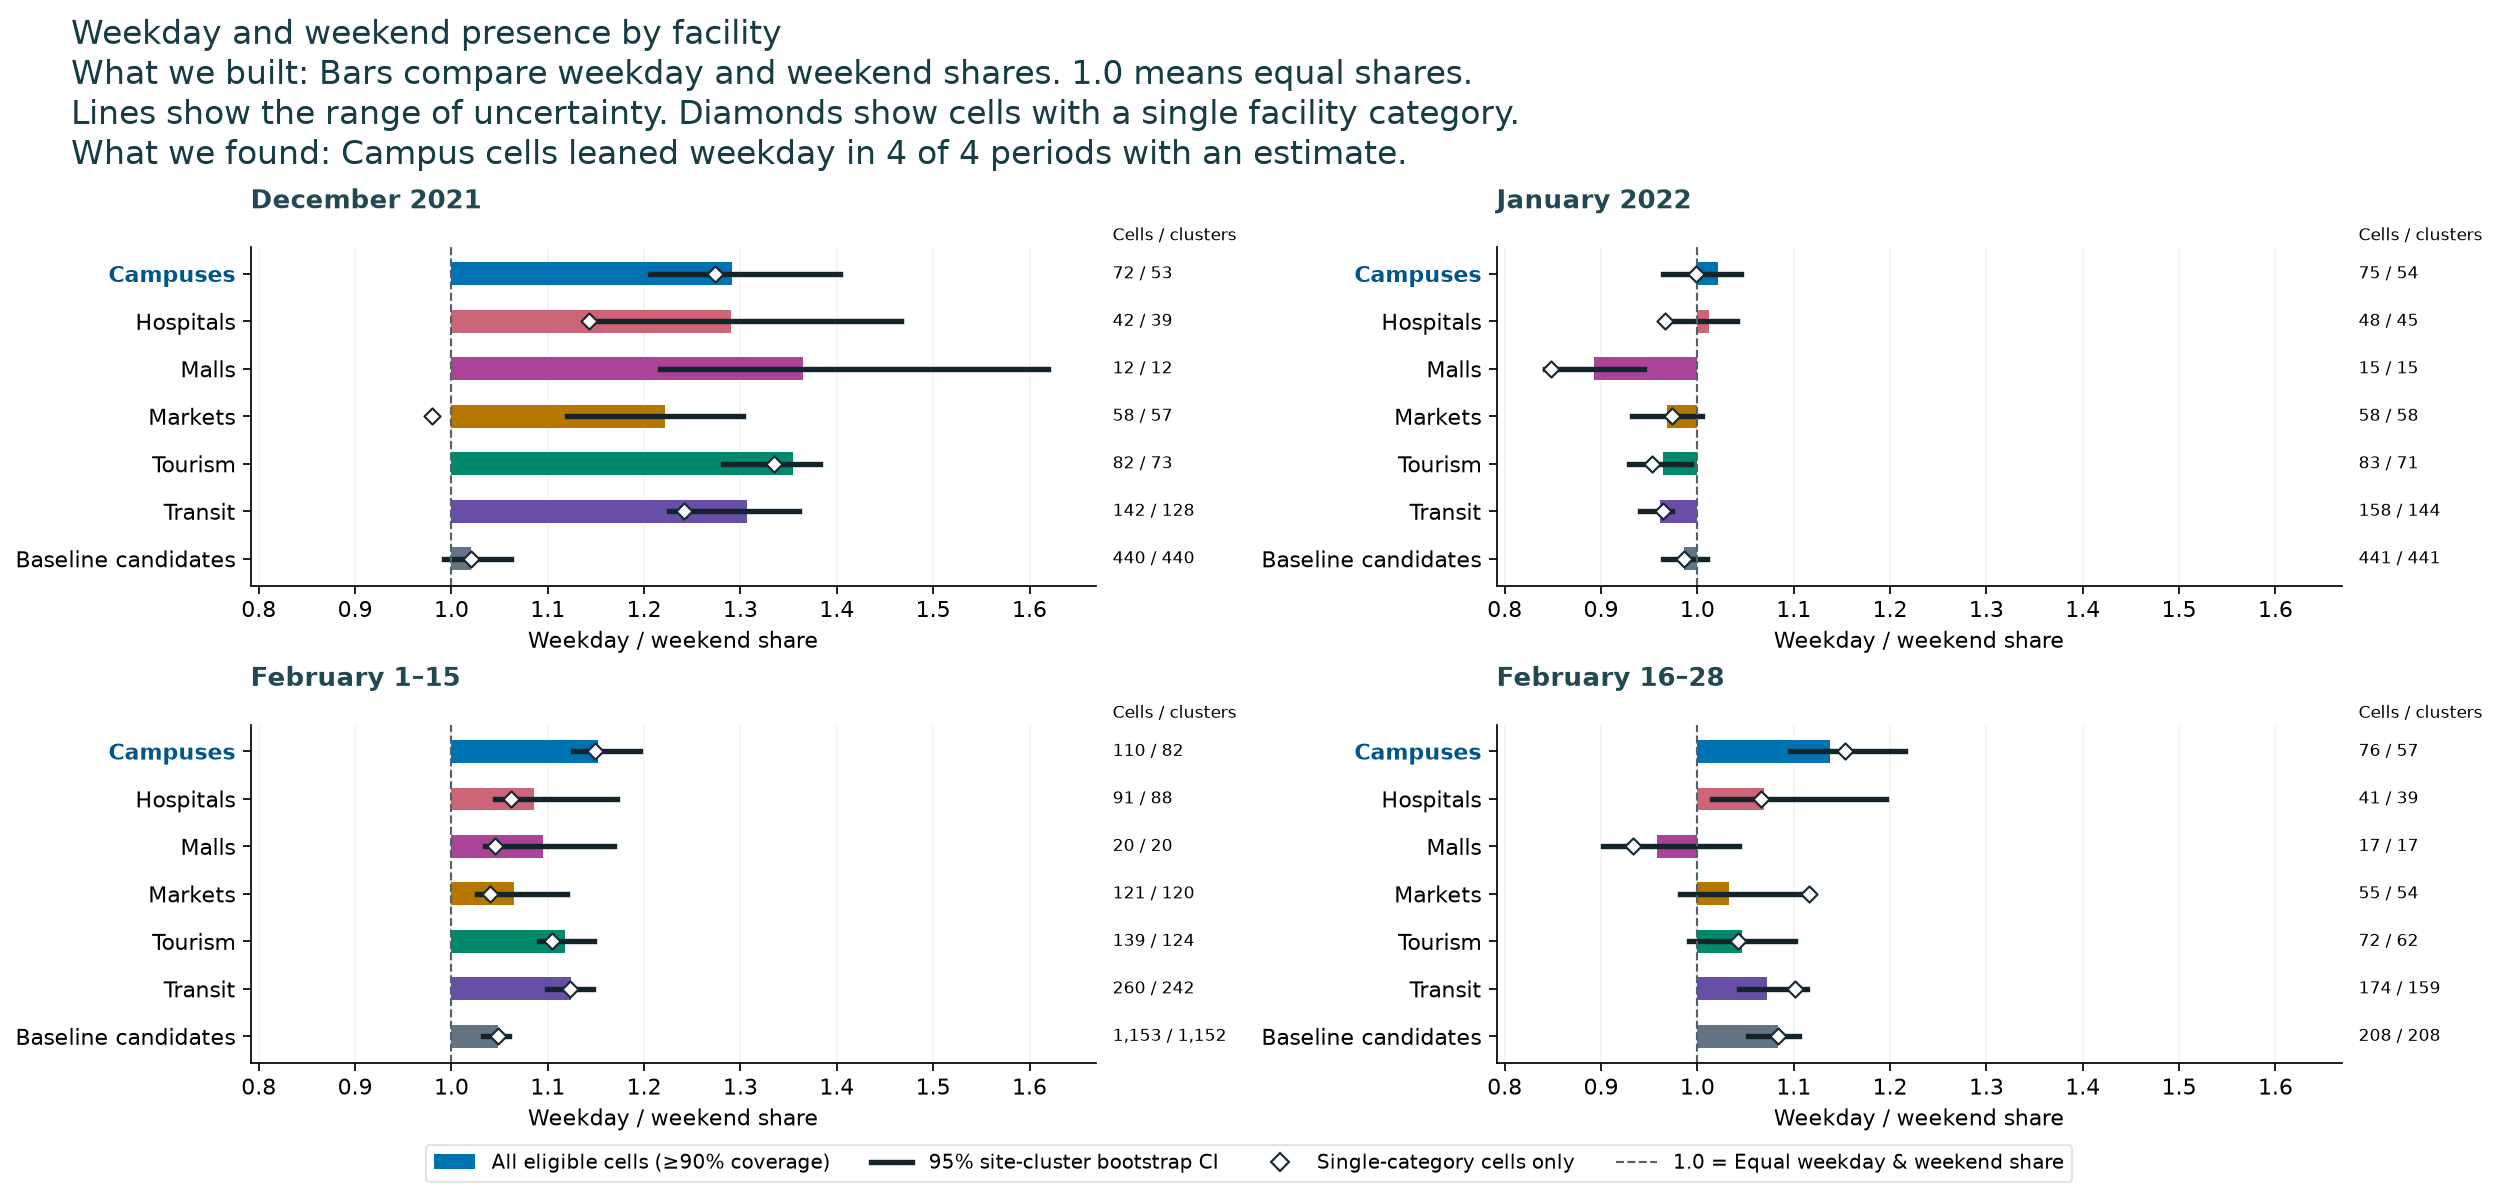

In [4]:
output = Path('weekday_weekend_ratio.png')
rhythm(output)
display(Image(filename=str(output)))